
# Homework 3 — Building a Library

**Topic:** European Digital Options and Bull Call Spreads

## Part (a): European Digital Option

In this homework, we extend the lecture's pricing library by implementing two new classes:

- `EuropeanDigitalContract`: defines the payoff of a cash-or-nothing European digital call or put option.
- `EuropeanDigitalAnalyticPricer`: calculates the fair value and Greeks using the Black-Scholes model.

A digital call pays 1 if the underlying price at expiry is above the strike, and 0 otherwise. A digital put pays 1 if the underlying price is below the strike, and 0 otherwise.

The fair value implementation was tested using `pytest`, with all 60 tests passing.

## Part (b): Digital Call as the Limit of a Bull Call Spread

A bull call spread combines a long European call at strike K and a short European call at strike K + ε.

When the price difference is divided by ε, the normalized bull call spread approaches the fair value of a digital call as ε approaches zero:

$$
D_{\text{call}}(K)
=
\lim_{\varepsilon \to 0^+}
\frac{C(K)-C(K+\varepsilon)}{\varepsilon}
$$

We will visualize this convergence using the analytic pricing classes implemented in the library.


### Visualization: Bull Call Spread vs. Digital Call

QuantCourseBP 86eecb1a159c790aeec4b97163993bae47b090be*


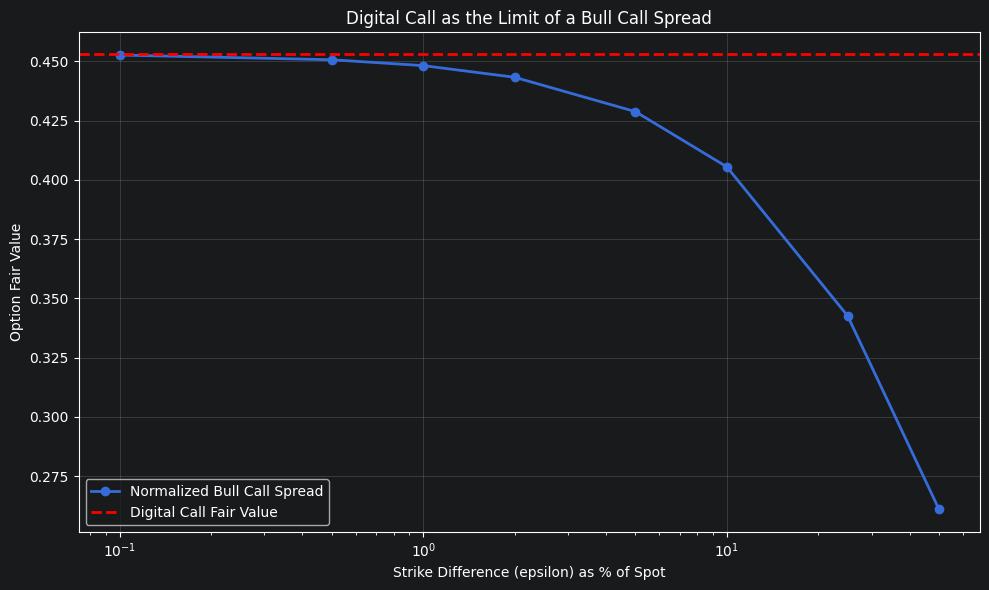

Digital Call Fair Value: 0.453137
Bull Spread (smallest epsilon): 0.452640


In [1]:

# Homework 3 - Part (b): Bull Call Spread vs. Digital Call

import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Locate the course repository and our Homework 3 library
current = Path.cwd().resolve()

repo_root = next(
    (
        p for p in [current, *current.parents]
        if (p / "src" / "enums.py").exists()
        and (p / "homeworks" / "83721eb" / "homeworks"
             / "homework3_library" / "pricer.py").exists()
    ),
    None
)

if repo_root is None:
    raise FileNotFoundError("Could not locate QuantCourseBP")

library_path = (
    repo_root / "homeworks" / "83721eb"
    / "homeworks" / "homework3_library"
)

sys.path.insert(0, str(repo_root))
sys.path.insert(0, str(library_path))

from contract import EuropeanContract, EuropeanDigitalContract
from pricer import (
    EuropeanAnalyticPricer,
    EuropeanDigitalAnalyticPricer,
    Params
)
from model import MarketModel
from src.enums import Stock, PutCallFwd, LongShort

# Market parameters
underlying = Stock.BLUECHIP_BANK
model = MarketModel(underlying)
params = Params()

S0 = model.spot
K = S0
T = 1.0

# Digital Call price
digital_contract = EuropeanDigitalContract(
    underlying, PutCallFwd.CALL, LongShort.LONG, K, T
)

digital_price = EuropeanDigitalAnalyticPricer(
    digital_contract, model, params
).calc_fair_value()

# Function for pricing a standard European Call
def call_price(strike):
    contract = EuropeanContract(
        underlying, PutCallFwd.CALL,
        LongShort.LONG, strike, T
    )
    return EuropeanAnalyticPricer(
        contract, model, params
    ).calc_fair_value()

# Bull spread approximation for decreasing strike differences
epsilon_fractions = np.array([
    0.001, 0.005, 0.01, 0.02,
    0.05, 0.10, 0.25, 0.50
])

epsilon_values = S0 * epsilon_fractions

call_at_K = call_price(K)

bull_spread_prices = [
    (call_at_K - call_price(K + eps)) / eps
    for eps in epsilon_values
]

# Visualization
plt.figure(figsize=(10, 6))

plt.plot(
    epsilon_fractions * 100,
    bull_spread_prices,
    "o-",
    linewidth=2,
    label="Normalized Bull Call Spread"
)

plt.axhline(
    digital_price,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Digital Call Fair Value"
)

plt.xscale("log")
plt.xlabel("Strike Difference (epsilon) as % of Spot")
plt.ylabel("Option Fair Value")
plt.title("Digital Call as the Limit of a Bull Call Spread")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Digital Call Fair Value: {digital_price:.6f}")
print(f"Bull Spread (smallest epsilon): {bull_spread_prices[0]:.6f}")


### Results and Interpretation

The figure demonstrates that the normalized bull call spread
converges to the fair value of a European digital call option.

For small values of epsilon, the bull spread approximation is
very close to the digital call price. As epsilon increases,
the approximation becomes less accurate.

This confirms that a European digital call can be interpreted
as the limit of a normalized bull call spread when the
difference between the two strike prices approaches zero.

### Conclusion


In Part (a), we extended the pricing library by implementing
`EuropeanDigitalContract` and `EuropeanDigitalAnalyticPricer`.
All 62 tests passed successfully using pytest, including
the fair value and numerical Greeks validation tests.


In Part (b), we verified the relationship between digital call
options and bull call spreads through numerical visualization.